# 1. DeFi EDA: Aave

Aave — децентрализованный протокол кредитования, который относится к категории Lending.
Пользователи вносят активы в пулы и могут брать займы под залог.
Здесь рассматриваются TVL Aave, рынок токена AAVE, распределение ликвидности по сетям и отдельные ончейн-показатели.
Для сравнения выбраны два других кредитных протокола: Compound и Morpho.

**Период анализа: 23.11.2025–21.11.2026**, 364 дневных наблюдения.
Данные получены 22.11.2026; незавершённый день исключён из основных временных рядов. Даты приведены к UTC, денежные показатели — к долларам США (USD).

## 2. Источники данных

| Источник | Полученные данные | Охват и способ получения |
|---|---|---|
| [DeFiLlama](https://api.llama.fi/protocol/aave) | TVL Aave, Compound, Morpho и сетей Aave; рейтинг протоколов | REST API, дневные ряды семейств протоколов |
| [CoinGecko](https://api.coingecko.com/api/v3/coins/aave/market_chart?vs_currency=usd&days=365&interval=daily) | Цена, капитализация и объём торгов AAVE за 24 часа | REST API, дневные наблюдения |
| [Etherscan](https://etherscan.io/address/0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9) | 18 последних прямых транзакций к контракту AAVE | HTML основной таблицы страницы контракта, 22.11.2026, 11:01:23–11:11:11 UTC |
| [web3.py](https://web3py.readthedocs.io/en/stable/) | Эмиссия AAVE и остаток AAVE на aAAVE в Ethereum | 14 исторических снимков через RPC и `eth_call` |
| [The Graph](https://github.com/aave/protocol-subgraphs) | Ставки резерва m.USDC Aave V3 в сети Metis | Subgraph на 0xGraph, 49 первых обновлений в 52 недельных окнах |

Etherscan описывает короткую выборку вызовов токена, а The Graph — один резерв в Metis.
Эти данные не являются годовой историей активности всего Aave. REST API Etherscan без ключа данных не вернул; использована именно HTML-страница.
Subgraph The Graph размещён по адресу `https://metisapi.0xgraph.xyz/subgraphs/name/aave/protocol-v3-metis`, отдельно от gateway The Graph Network.

Ниже приведены примеры исходных запросов. Они оставлены как текст: последовательное выполнение ячеек повторяет анализ **встроенного снимка**, без новых запросов и API-ключей.

<details>
<summary>DeFiLlama и CoinGecko: адреса и параметры запросов</summary>

```python
import requests

protocols = {
    name: requests.get(f"https://api.llama.fi/protocol/{slug}", timeout=60).json()
    for name, slug in [("Aave", "aave"), ("Compound", "compound-finance"), ("Morpho", "morpho")]
}
ranking = requests.get("https://api.llama.fi/protocols", timeout=60).json()
market = requests.get(
    "https://api.coingecko.com/api/v3/coins/aave/market_chart",
    params={"vs_currency": "usd", "days": 365, "interval": "daily"}, timeout=60
).json()
```

В DeFiLlama использованы поля `tvl` и `chainTvls`, в CoinGecko — `prices`, `market_caps`, `total_volumes`.
Не складываются родительские и дочерние протоколы; категории `borrowed`, `staking`, `pool2`, `vesting`, `offers`, `doublecounted` и их сетевые суффиксы исключены.
Запрос CoinGecko с `days=365` задаёт скользящий период: новый вызов даст другой снимок. В работе зафиксирован ответ от 22.11.2026.

</details>

<details>
<summary>Etherscan: получение и разбор HTML</summary>

```python
import requests
from bs4 import BeautifulSoup

token = "0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9"
headers = {"User-Agent": "Mozilla/5.0 (Aave educational EDA)"}
token_html = requests.get(f"https://etherscan.io/token/{token}", headers=headers, timeout=60).text
html = requests.get(f"https://etherscan.io/address/{token}", headers=headers, timeout=60).text
rows = []
for row in BeautifulSoup(html, "html.parser").select("#table-view-tab-pane tbody tr"):
    tx = row.select_one('a[href^="/tx/0x"]')
    block = row.select_one('a[href^="/block/"]')
    date = row.select_one(".showDate")
    method = row.select_one(".td_functionNameOri")
    if tx and block and date:
        rows.append({"tx_hash": tx["href"].split("/")[-1],
                     "block_number": int(block.get_text(strip=True)),
                     "timestamp_utc": date.get_text(strip=True),
                     "method": method.get_text(" ", strip=True) if method else "unknown"})
```

Взяты только записи основной таблицы с блоком и временем; соседние вкладки и неподтверждённые транзакции исключены.
Разметка и последние транзакции со временем меняются. Это прямые вызовы контракта токена, а не все события `Transfer` и не все операции Aave.

</details>

<details>
<summary>web3.py: исторические вызовы Ethereum</summary>

```python
import requests
import pandas as pd
from web3 import Web3

w3 = Web3(Web3.HTTPProvider("https://eth-mainnet.public.blastapi.io", request_kwargs={"timeout": 60}))
token = Web3.to_checksum_address("0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9")
a_token = Web3.to_checksum_address("0xA700b4eB416Be35b2911fd5Dee80678ff64fF6C9")
abi = [
    {"name": "totalSupply", "type": "function", "stateMutability": "view", "inputs": [], "outputs": [{"type": "uint256"}]},
    {"name": "decimals", "type": "function", "stateMutability": "view", "inputs": [], "outputs": [{"type": "uint8"}]},
    {"name": "balanceOf", "type": "function", "stateMutability": "view", "inputs": [{"name": "account", "type": "address"}], "outputs": [{"type": "uint256"}]}
]
contract = w3.eth.contract(address=token, abi=abi)
decimals = contract.functions.decimals().call()
start, end = pd.Timestamp("2025-11-23", tz="UTC"), pd.Timestamp("2026-11-21", tz="UTC")
dates = sorted(set([start, end] + list(pd.date_range(start, end, freq="MS"))))
samples = []
for date in dates:
    info = requests.get(f"https://coins.llama.fi/block/ethereum/{int(date.timestamp())}", timeout=60).json()
    block = w3.eth.get_block(int(info["height"]))
    samples.append({"block_number": block["number"], "block_timestamp": block["timestamp"],
                    "total_supply_raw": str(contract.functions.totalSupply().call(block_identifier=block["number"])),
                    "aave_cash_raw": str(contract.functions.balanceOf(a_token).call(block_identifier=block["number"]))})
```

Сеть — Ethereum (`chain_id=1`), методы RPC — `eth_chainId`, `eth_getBlockByNumber`, `eth_call`.
Адрес aAAVE взят из [адресной книги Aave](https://raw.githubusercontent.com/bgd-labs/aave-address-book/main/src/AaveV3Ethereum.sol), поле `AAVE_A_TOKEN`.
DeFiLlama Block API использован только для выбора блока по времени. Сам остаток получен из Ethereum через web3.py; он измеряет доступный AAVE одного резерва, а не общий TVL.
Для нового запроса нужен RPC с доступом к историческому состоянию. Номера, хеши и время использованных блоков включены во встроенный снимок.

</details>

<details>
<summary>The Graph: запрос резерва и недельной истории Metis</summary>

```python
import requests
import pandas as pd

url = "https://metisapi.0xgraph.xyz/subgraphs/name/aave/protocol-v3-metis"
query = "{ _meta { block { number timestamp } hasIndexingErrors } reserves(first:100) { id symbol decimals } }"
reserves = requests.post(url, json={"query": query}, timeout=60).json()["data"]["reserves"]
reserve = next(r["id"] for r in reserves if r["symbol"] == "m.USDC")
dates = pd.date_range("2025-11-23", "2026-11-21", freq="7D", tz="UTC")
history = []
for batch in range(0, len(dates), 10):
    parts = []
    for i, date in enumerate(dates[batch:batch+10]):
        begin = int(date.timestamp())
        finish = min(begin + 7*86400, 1795305600)  # 22.11.2026 00:00 UTC
        parts.append(
            f'd{i}: reserveParamsHistoryItems(first:1, orderBy:timestamp, orderDirection:asc, '
            f'where:{{reserve:"{reserve}",timestamp_gte:{begin},timestamp_lt:{finish}}}) '
            '{ id timestamp liquidityRate variableBorrowRate availableLiquidity }'
        )
    response = requests.post(url, json={"query": "{" + "\n".join(parts) + "}"}, timeout=60).json()
    for entries in response["data"].values():
        history.extend(entries)
```

Точный идентификатор резерва: `0xea32a96608495e54156ae48931a7c20f0dcc1a210xb9fabd7500b2c6781c35dd48d54f81fc2299d7af` (m.USDC, 6 знаков).
Берётся первое обновление каждого окна, а не средняя недельная ставка. Из 52 окон три не содержали записей; они не заполнялись.
Годовая ставка APR рассчитана как `liquidityRate / 10**27 * 100`, ставка переменного займа — аналогично из `variableBorrowRate`.

</details>

## 3. Загрузка и подготовка данных

В ноутбук включены реальные ряды из сохранённых ответов источников: TVL и сети за выбранный период,
исходные наблюдения CoinGecko, The Graph и web3.py, а также извлечённая таблица Etherscan.
Числа не округлялись при встраивании. Для компактности JSON сжат и записан в Base64; ячейка с ним свёрнута.
Анализ использует pandas и matplotlib, без внешних файлов и интернета.

In [1]:
import base64
import json
import zlib

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

START = pd.Timestamp("2025-11-23")
END = pd.Timestamp("2026-11-21")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13,
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.22,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#2876A1", "#D28B32", "#399B7F", "#8F68AA", "#D76B72", "#9AA3AD"])
})

def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
    ax.set_xlabel("Дата (UTC)")

def growth(series):
    return (series.iloc[-1] / series.iloc[0] - 1) * 100

In [2]:
# Реальный снимок данных, полученный 22.11.2026.
packed_data = """
...
"""
snapshot = json.loads(zlib.decompress(base64.b64decode(packed_data)))

Unix-время переведено в даты UTC. Если на одну дату приходится несколько точек, оставлена последняя.
Для сравнения TVL и рынка токена используются общие даты без интерполяции.
Нули до начала истории отдельных сетей означают отсутствие их вклада в ряде DeFiLlama; внутренние пропуски не заполняются.

In [3]:
def daily_series(rows, name, unit="s"):
    frame = pd.DataFrame(rows, columns=["timestamp", "value"]).sort_values("timestamp")
    frame["date"] = pd.to_datetime(frame["timestamp"], unit=unit, utc=True).dt.tz_localize(None).dt.normalize()
    frame = frame.loc[frame["date"].between(START, END)].drop_duplicates("date", keep="last")
    return frame.set_index("date")["value"].astype(float).rename(name)

tvl = pd.concat([daily_series(rows, name) for name, rows in snapshot["tvl"].items()], axis=1)
market = pd.concat([
    daily_series(snapshot["market"][field], name, unit="ms")
    for field, name in [("prices", "price_usd"), ("market_caps", "market_cap_usd"), ("total_volumes", "volume_24h_usd")]
], axis=1)
common = tvl.join(market, how="inner").dropna().sort_index()

chain_series = []
for name, rows in snapshot["chains"].items():
    series = daily_series(rows, name)
    if not series.empty:
        aligned = series.reindex(common.index)
        aligned.loc[aligned.index < series.index.min()] = 0
        chain_series.append(aligned)
chains = pd.concat(chain_series, axis=1)

graph = pd.DataFrame(snapshot["graph"]).drop_duplicates("id").sort_values("timestamp")
graph["date"] = pd.to_datetime(graph["timestamp"].astype("int64"), unit="s", utc=True).dt.tz_localize(None)
graph["supply_apr_pct"] = graph["liquidityRate"].map(lambda x: int(x) / 10**27 * 100)
graph["borrow_apr_pct"] = graph["variableBorrowRate"].map(lambda x: int(x) / 10**27 * 100)
rpc = pd.DataFrame(snapshot["rpc"]["samples"]).sort_values("block_timestamp")
rpc["date"] = pd.to_datetime(rpc["block_timestamp"], unit="s", utc=True).dt.tz_localize(None)
rpc["total_supply_aave"] = rpc["total_supply_raw"].map(int) / 10**18
rpc["aave_v3_cash_aave"] = rpc["aave_cash_raw"].map(int) / 10**18
tx = pd.DataFrame(snapshot["transactions"]).drop_duplicates("tx_hash")
tx["timestamp_utc"] = pd.to_datetime(tx["timestamp_utc"], utc=True)

ranking = pd.DataFrame(snapshot["ranking"]).sort_values("tvl", ascending=False).reset_index(drop=True)
aave_rank = int(ranking.index[ranking["name"].eq("Aave V3")][0]) + 1
assert aave_rank <= 50
assert common.index.equals(pd.date_range(START, END, name="date"))
assert common.gt(0).all().all() and chains.ge(0).all().all()
assert (chains.sum(axis=1) - common["Aave"]).abs().div(common["Aave"]).max() < 0.005

display(Markdown(
    f"После объединения осталось **{len(common)} дат без пропусков**. "
    f"В снимке DeFiLlama Aave V3 занимает **{aave_rank}-е место** по TVL после исключения CEX, "
    "то есть входит в top-50. Основной анализ ниже относится к семейству Aave."
))
preview = common[["Aave", "price_usd", "market_cap_usd", "volume_24h_usd"]].head(3).copy()
preview["Aave"] /= 1e9
preview["market_cap_usd"] /= 1e9
preview["volume_24h_usd"] /= 1e6
preview.columns = ["TVL Aave, млрд USD", "Цена AAVE, USD", "Капитализация, млрд USD", "Объём за 24 ч, млн USD"]
preview.index = preview.index.strftime("%d.%m.%Y")
preview.index.name = "Дата"
display(preview.round(2))

После объединения осталось **364 дат без пропусков**. В снимке DeFiLlama Aave V3 занимает **3-е место** по TVL после исключения CEX, то есть входит в top-50. Основной анализ ниже относится к семейству Aave.

,"TVL Aave, млрд USD","Цена AAVE, USD","Капитализация, млрд USD","Объём за 24 ч, млн USD"
Дата,,,,
23.11.2025,28.27,161.12,2.44,264.74
24.11.2025,29.66,167.01,2.53,267.92
25.11.2025,30.72,178.58,2.71,350.75


## 4. Анализ и графики

### 4.1. Исторический TVL Aave

Используется опубликованный DeFiLlama TVL семейства Aave. Долларовый TVL зависит и от количества активов, и от их цен, поэтому его изменение не равно чистому притоку или оттоку средств.

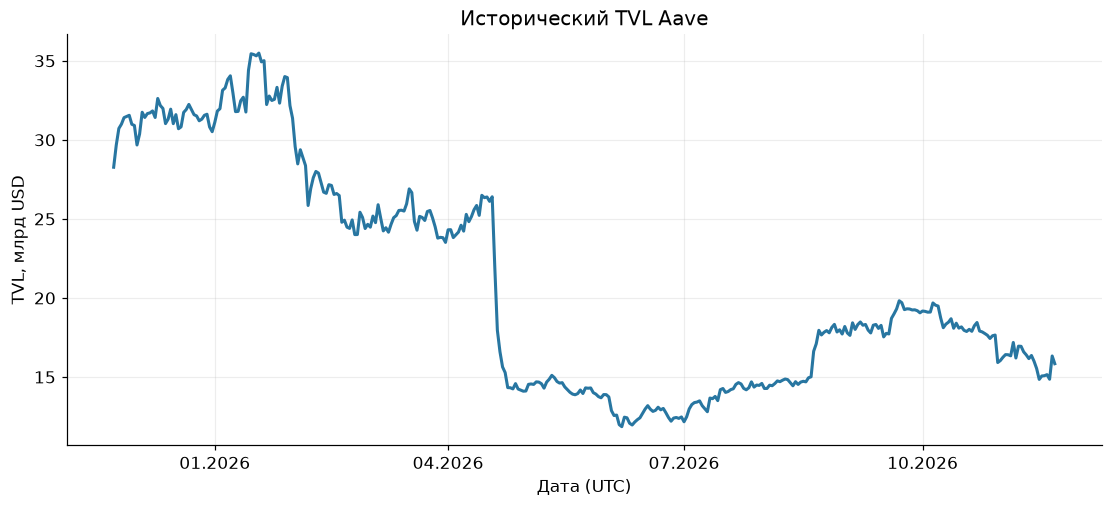

TVL снизился с **28.27 до 15.84 млрд USD** (**-44.0%**). Наибольшее дневное снижение — **-18.3%** (20.04.2026); по одному ряду нельзя установить причину этого движения.

In [4]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(common.index, common["Aave"] / 1e9, linewidth=2)
ax.set(title="Исторический TVL Aave", ylabel="TVL, млрд USD")
date_axis(ax)
plt.show()

tvl_daily_change = common["Aave"].pct_change() * 100
worst_date = tvl_daily_change.idxmin()
display(Markdown(
    f"TVL снизился с **{common['Aave'].iloc[0]/1e9:.2f} до {common['Aave'].iloc[-1]/1e9:.2f} млрд USD** "
    f"(**{growth(common['Aave']):.1f}%**). "
    f"Наибольшее дневное снижение — **{tvl_daily_change.loc[worst_date]:.1f}%** ({worst_date:%d.%m.%Y}); "
    "по одному ряду нельзя установить причину этого движения."
))

### 4.2. TVL Aave, Compound и Morpho

Сравнение выполнено на одинаковых датах по родительским рядам DeFiLlama, без добавления TVL дочерних версий.

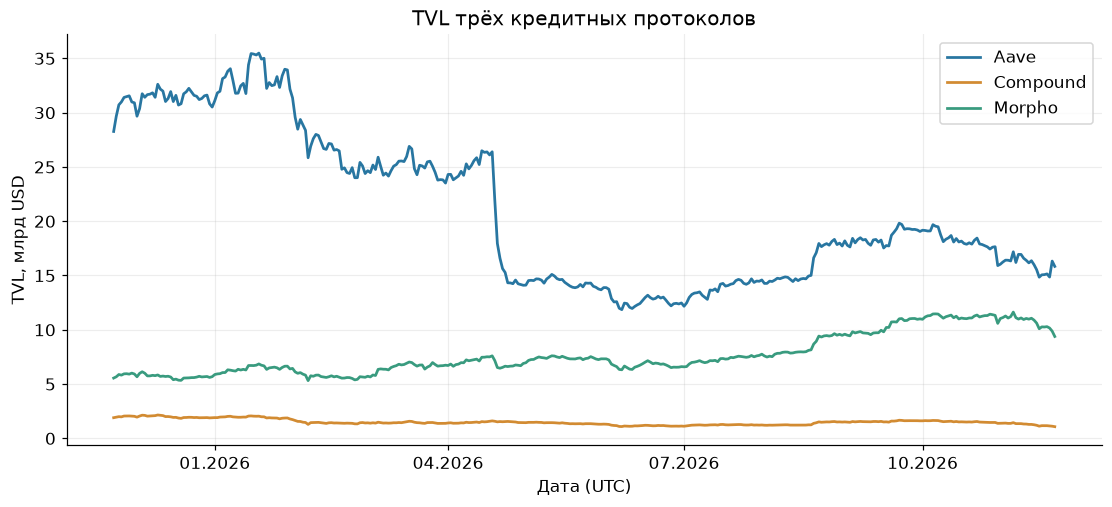

Morpho увеличил TVL на **69.0%**, тогда как Compound потерял **43.5%**. На конец периода Aave остаётся крупнейшим из трёх: его TVL в **1.69 раза** выше Morpho.

In [5]:
fig, ax = plt.subplots(layout="constrained")
for name in ["Aave", "Compound", "Morpho"]:
    ax.plot(common.index, common[name] / 1e9, label=name, linewidth=1.8)
ax.set(title="TVL трёх кредитных протоколов", ylabel="TVL, млрд USD")
ax.legend()
date_axis(ax)
plt.show()
display(Markdown(
    f"Morpho увеличил TVL на **{growth(common['Morpho']):.1f}%**, "
    f"тогда как Compound потерял **{-growth(common['Compound']):.1f}%**. "
    f"На конец периода Aave остаётся крупнейшим из трёх: его TVL в **{common['Aave'].iloc[-1]/common['Morpho'].iloc[-1]:.2f} раза** выше Morpho."
))

### 4.3. Цена токена AAVE

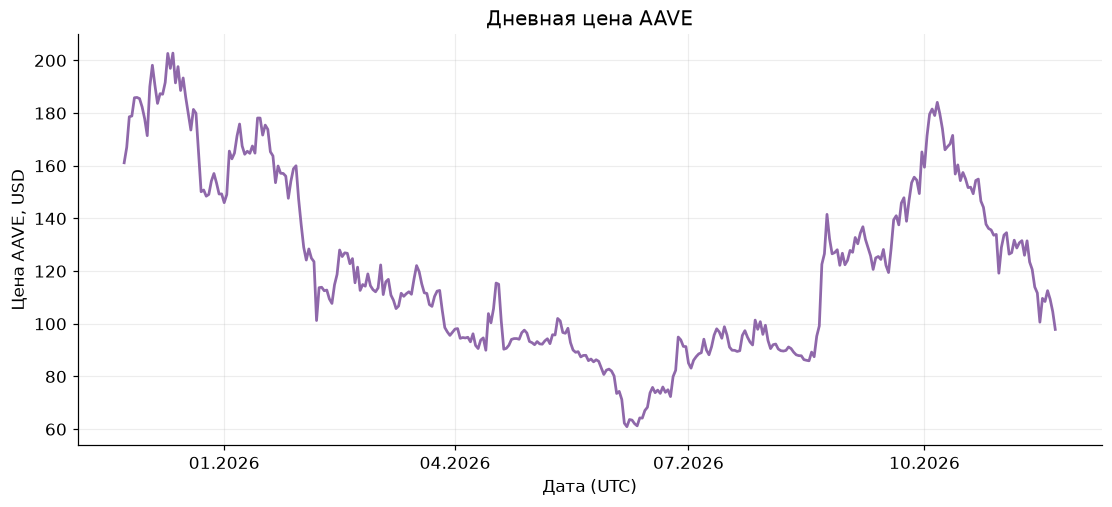

Цена AAVE снизилась с **161.12 до 97.85 USD** (**-39.3%**). Дневные наблюдения лежат в диапазоне **60.93–202.75 USD**.

In [6]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(common.index, common["price_usd"], color="#8F68AA", linewidth=1.8)
ax.set(title="Дневная цена AAVE", ylabel="Цена AAVE, USD")
date_axis(ax)
plt.show()
display(Markdown(
    f"Цена AAVE снизилась с **{common['price_usd'].iloc[0]:.2f} до {common['price_usd'].iloc[-1]:.2f} USD** "
    f"(**{growth(common['price_usd']):.1f}%**). "
    f"Дневные наблюдения лежат в диапазоне **{common['price_usd'].min():.2f}–{common['price_usd'].max():.2f} USD**."
))

### 4.4. Капитализация и торговый объём AAVE

Объём CoinGecko относится к торговле токеном за последние 24 часа на момент наблюдения, а не к выдаче кредитов в Aave.

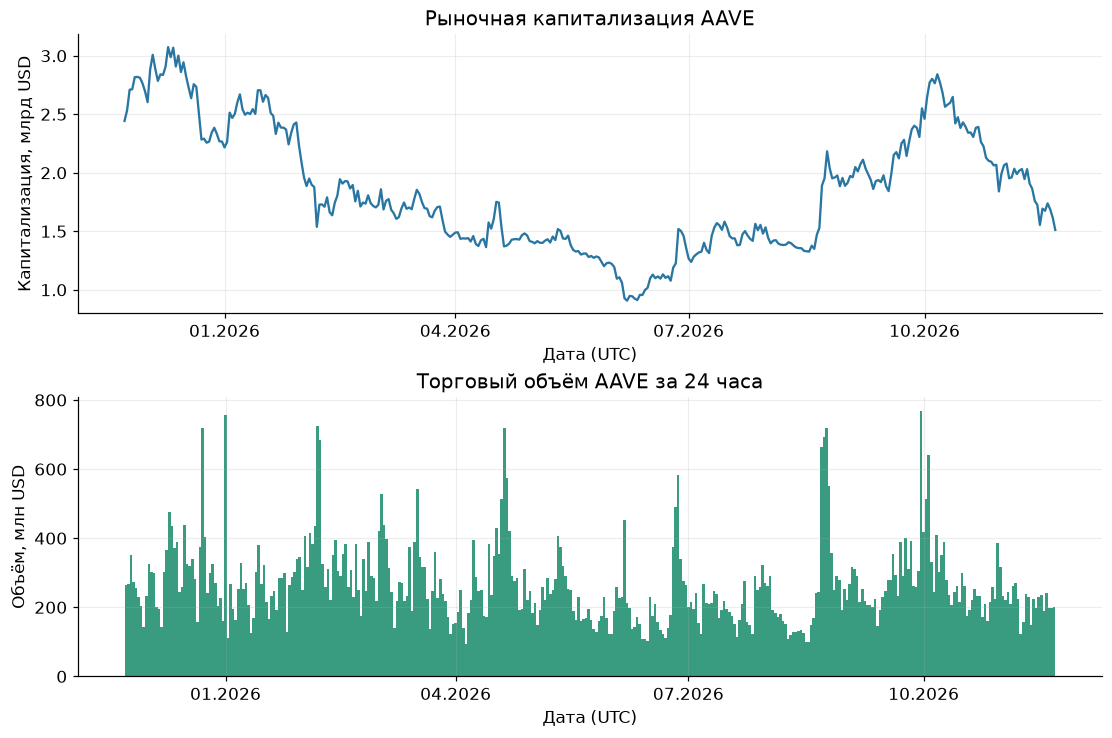

Капитализация изменилась с **2.44 до 1.51 млрд USD**. Медианный объём торгов за 24 часа составил **244.5 млн USD**, максимальный — **0.77 млрд USD**.

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), layout="constrained")
axes[0].plot(common.index, common["market_cap_usd"] / 1e9)
axes[0].set(title="Рыночная капитализация AAVE", ylabel="Капитализация, млрд USD")
axes[1].bar(common.index, common["volume_24h_usd"] / 1e6, width=1, color="#399B7F")
axes[1].set(title="Торговый объём AAVE за 24 часа", ylabel="Объём, млн USD")
for ax in axes:
    date_axis(ax)
plt.show()
display(Markdown(
    f"Капитализация изменилась с **{common['market_cap_usd'].iloc[0]/1e9:.2f} до {common['market_cap_usd'].iloc[-1]/1e9:.2f} млрд USD**. "
    f"Медианный объём торгов за 24 часа составил **{common['volume_24h_usd'].median()/1e6:.1f} млн USD**, "
    f"максимальный — **{common['volume_24h_usd'].max()/1e9:.2f} млрд USD**."
))

### 4.5. TVL Aave по основным блокчейнам

Выбраны пять крупнейших сетей по TVL на 21.11.2026; остальные объединены в категорию «Другие».

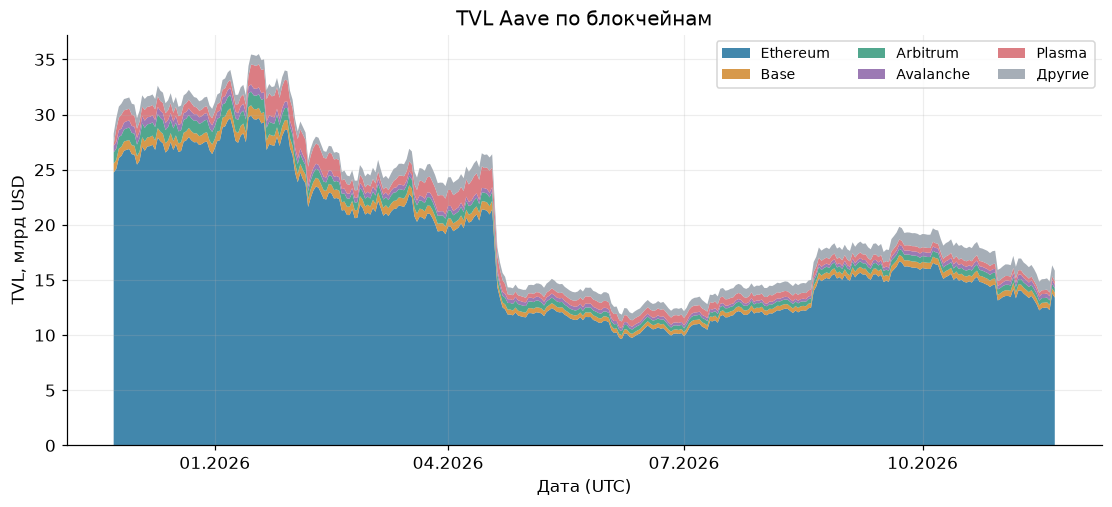

На Ethereum приходится **84.6%** TVL, на Base — **2.7%**, на Arbitrum — **2.4%**. Пять крупнейших сетей вместе дают **94.0%**: ликвидность сильно сосредоточена в Ethereum.

In [8]:
chain_shares = (chains.iloc[-1] / common["Aave"].iloc[-1] * 100).sort_values(ascending=False)
top_chains = list(chain_shares.head(5).index)
chain_plot = chains[top_chains].copy()
chain_plot["Другие"] = chains.drop(columns=top_chains).sum(axis=1)
fig, ax = plt.subplots(layout="constrained")
ax.stackplot(chain_plot.index, *[chain_plot[c] / 1e9 for c in chain_plot], labels=chain_plot.columns, alpha=0.88)
ax.set(title="TVL Aave по блокчейнам", ylabel="TVL, млрд USD")
ax.legend(loc="upper right", ncol=3, fontsize=9)
date_axis(ax)
plt.show()
display(Markdown(
    f"На Ethereum приходится **{chain_shares['Ethereum']:.1f}%** TVL, "
    f"на Base — **{chain_shares['Base']:.1f}%**, на Arbitrum — **{chain_shares['Arbitrum']:.1f}%**. "
    f"Пять крупнейших сетей вместе дают **{chain_shares.head(5).sum():.1f}%**: ликвидность сильно сосредоточена в Ethereum."
))

### 4.6. Относительная динамика TVL и цены AAVE

Оба показателя приведены к 100 на 23.11.2025: `индекс = значение / начальное значение × 100`.

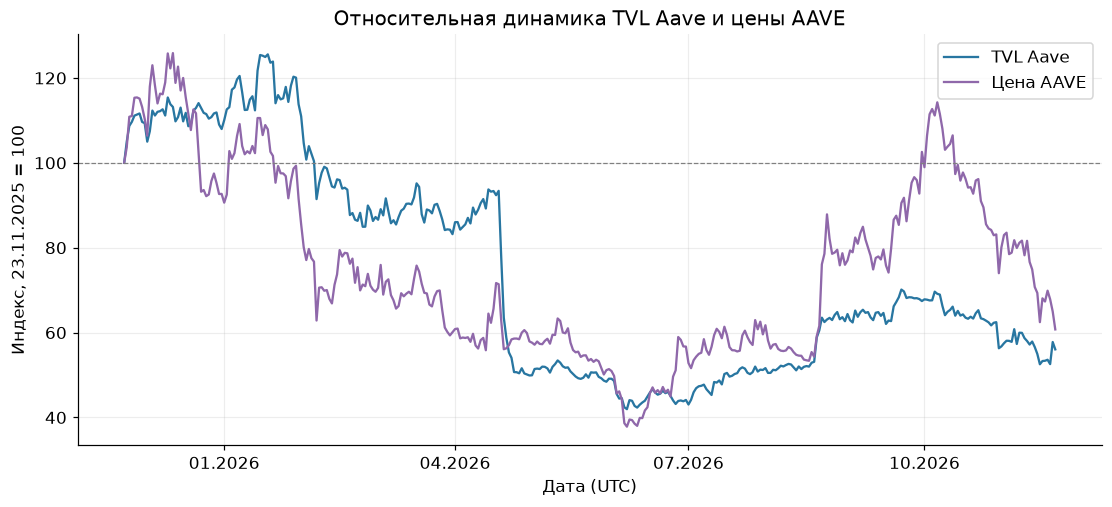

Индекс TVL завершил период на **56.0**, индекс цены — на **60.7**. TVL снизился на **4.7 процентного пункта** сильнее цены токена; их относительная динамика различается.

In [9]:
indexed = common[["Aave", "price_usd"]].div(common[["Aave", "price_usd"]].iloc[0]) * 100
fig, ax = plt.subplots(layout="constrained")
ax.plot(indexed.index, indexed["Aave"], label="TVL Aave")
ax.plot(indexed.index, indexed["price_usd"], label="Цена AAVE", color="#8F68AA")
ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
ax.set(title="Относительная динамика TVL Aave и цены AAVE", ylabel="Индекс, 23.11.2025 = 100")
ax.legend()
date_axis(ax)
plt.show()
display(Markdown(
    f"Индекс TVL завершил период на **{indexed['Aave'].iloc[-1]:.1f}**, индекс цены — на **{indexed['price_usd'].iloc[-1]:.1f}**. "
    f"TVL снизился на **{growth(common['price_usd'])-growth(common['Aave']):.1f} процентного пункта** сильнее цены токена; "
    "их относительная динамика различается."
))

### 4.7. Ончейн-показатели

Три панели показывают разные срезы: ставки m.USDC в Metis из The Graph, доступный остаток AAVE на aAAVE в Ethereum через web3.py и методы прямых вызовов AAVE из HTML Etherscan.
На первой панели дата означает начало недельного окна, ставка — первое обновление внутри него; три пустых окна оставлены разрывами.
На второй панели использовано фактическое время блока, которое может немного предшествовать запрошенной дате.

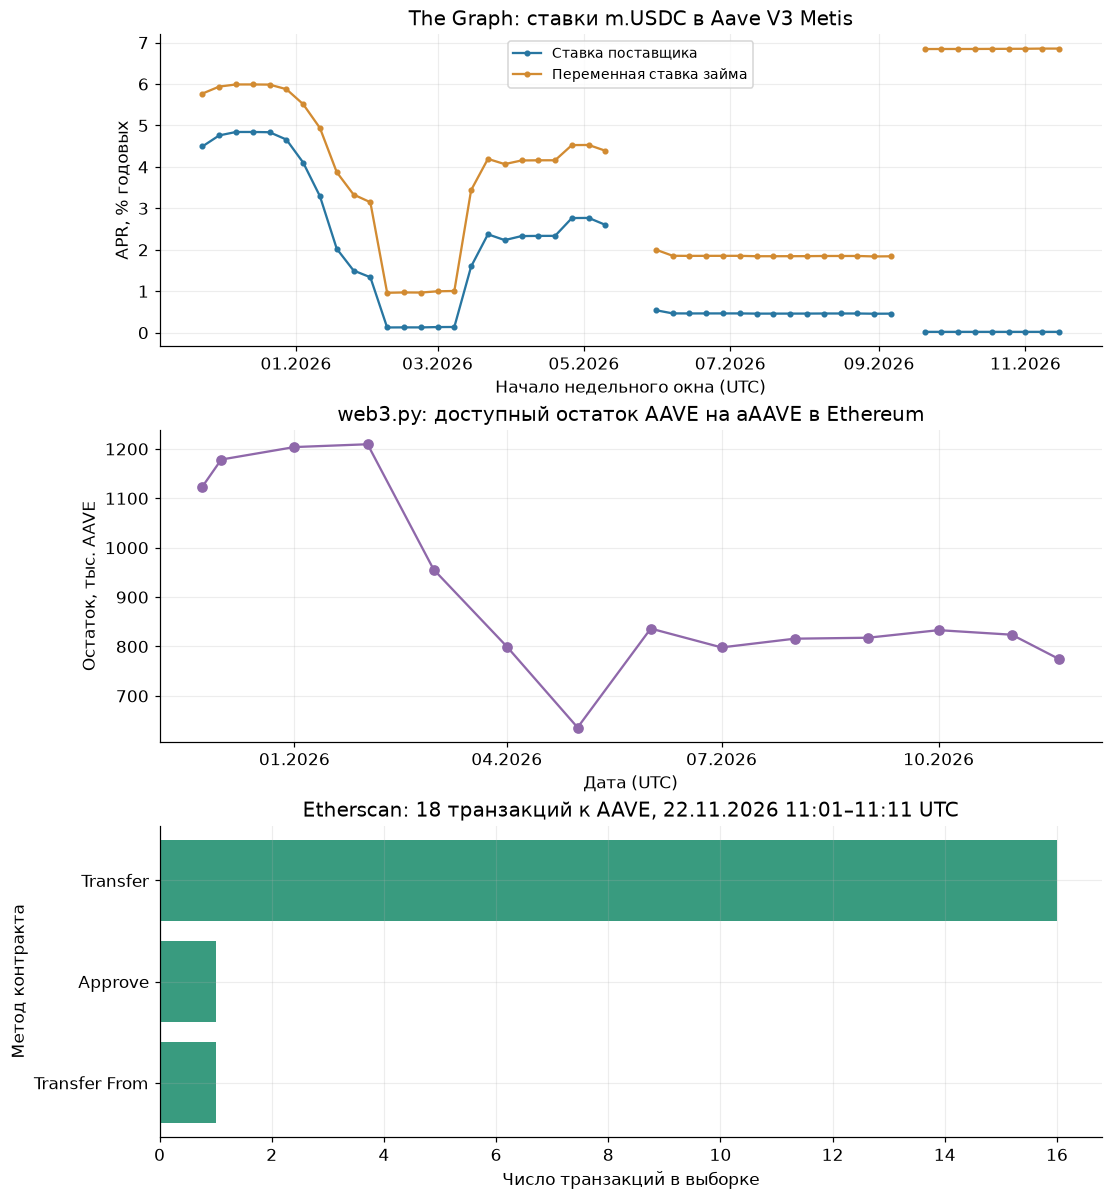

Медианная ставка поставщика m.USDC по **49 наблюдениям** составила **0.464% годовых**. В **14 снимках** остаток AAVE на aAAVE изменился с **1,123,549 до 774,556 AAVE**, эмиссия токена оставалась **16 млн AAVE**. В короткой HTML-выборке Etherscan чаще всего встречался метод **Transfer** (**16 из 18 транзакций**); эти частоты нельзя переносить на весь период.

In [10]:
graph["week_start"] = START + pd.to_timedelta((graph["date"] - START).dt.days // 7 * 7, unit="D")
weekly_rates = graph.set_index("week_start")[["supply_apr_pct", "borrow_apr_pct"]].reindex(pd.date_range(START, END, freq="7D"))
fig, axes = plt.subplots(3, 1, figsize=(10, 10.8), layout="constrained")
axes[0].plot(weekly_rates.index, weekly_rates["supply_apr_pct"], marker=".", label="Ставка поставщика")
axes[0].plot(weekly_rates.index, weekly_rates["borrow_apr_pct"], marker=".", label="Переменная ставка займа")
axes[0].set(title="The Graph: ставки m.USDC в Aave V3 Metis", ylabel="APR, % годовых")
date_axis(axes[0])
axes[0].set_xlabel("Начало недельного окна (UTC)")
axes[0].legend(fontsize=9)
axes[1].plot(rpc["date"], rpc["aave_v3_cash_aave"] / 1000, marker="o", color="#8F68AA")
axes[1].set(title="web3.py: доступный остаток AAVE на aAAVE в Ethereum", ylabel="Остаток, тыс. AAVE")
date_axis(axes[1])
methods = tx["method"].value_counts().sort_values()
axes[2].barh(methods.index, methods.values, color="#399B7F")
axes[2].set(title="Etherscan: 18 транзакций к AAVE, 22.11.2026 11:01–11:11 UTC", xlabel="Число транзакций в выборке", ylabel="Метод контракта")
axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.show()
display(Markdown(
    f"Медианная ставка поставщика m.USDC по **{len(graph)} наблюдениям** составила **{graph['supply_apr_pct'].median():.3f}% годовых**. "
    f"В **{len(rpc)} снимках** остаток AAVE на aAAVE изменился с **{rpc['aave_v3_cash_aave'].iloc[0]:,.0f} до {rpc['aave_v3_cash_aave'].iloc[-1]:,.0f} AAVE**, "
    f"эмиссия токена оставалась **{rpc['total_supply_aave'].iloc[-1]/1e6:.0f} млн AAVE**. "
    f"В короткой HTML-выборке Etherscan чаще всего встречался метод **{methods.idxmax()}** "
    f"(**{methods.max()} из {len(tx)} транзакций**); эти частоты нельзя переносить на весь период."
))

## 5. Сравнение с конкурентами

Начальные и конечные значения взяты на общие даты — 23.11.2025 и 21.11.2026.
Изменение рассчитано как `(конечный TVL / начальный TVL − 1) × 100%`.

In [11]:
competitors = pd.DataFrame({
    "TVL 23.11.2025, млрд USD": common[["Aave", "Compound", "Morpho"]].iloc[0] / 1e9,
    "TVL 21.11.2026, млрд USD": common[["Aave", "Compound", "Morpho"]].iloc[-1] / 1e9,
    "Изменение, %": common[["Aave", "Compound", "Morpho"]].apply(growth)
})
competitors.index.name = "Протокол"
display(competitors.round(2))
display(Markdown(
    f"Morpho показал лучший относительный результат, но Aave сохраняет **{common['Aave'].iloc[-1]/common[['Aave','Compound','Morpho']].iloc[-1].sum()*100:.1f}%** "
    "суммарного TVL выбранной тройки. Эта доля не относится ко всему рынку кредитования."
))

,"TVL 23.11.2025, млрд USD","TVL 21.11.2026, млрд USD","Изменение, %"
Протокол,,,
Aave,28.27,15.84,-43.97
Compound,1.90,1.07,-43.51
Morpho,5.55,9.38,68.99


Morpho показал лучший относительный результат, но Aave сохраняет **60.2%** суммарного TVL выбранной тройки. Эта доля не относится ко всему рынку кредитования.

## 6. Основные выводы

- TVL Aave снизился с **28,27 до 15,84 млрд USD (−44,0%)**. Самый резкий дневной спад в ряде пришёлся на 20.04.2026 (−18,3%); причина по этим данным не определяется.
- Цена AAVE упала с **161,12 до 97,85 USD (−39,3%)**. Снижение TVL было на 4,7 процентного пункта сильнее снижения цены токена.
- У Compound TVL сократился на **43,5%**, а у Morpho вырос на **69,0%**. При этом Aave завершил период с наибольшим TVL среди трёх протоколов.
- Ликвидность распределена неравномерно: **84,6% TVL приходится на Ethereum**, 2,7% — на Base и 2,4% — на Arbitrum. Пять крупнейших сетей дают 94,0% TVL.
- Медианная ставка поставщика m.USDC в Metis составила **0,464% годовых**; доступный остаток AAVE на aAAVE в Ethereum уменьшился с **1,124 до 0,775 млн AAVE**. Эти показатели характеризуют отдельные резервы, а HTML-выборка Etherscan — только десятиминутный срез вызовов токена.

## 7. Использование LLM и MCP

При подготовке использован ИИ-помощник **OpenAI Codex**: для написания Python-кода, оформления пояснений,
проверки расчётов и переработки ноутбука. Данные взяты из реальных ответов источников, а не созданы моделью.

MCP использован отдельно для чтения готовых результатов. Локальный сервер `Aave EDA` предоставлял
`get_analysis_summary` и `get_data_sources`; сохранённое взаимодействие от 22.11.2026 содержит инициализацию,
список инструментов и ответы на оба вызова. Загрузка данных выполнялась Python-запросами, без MCP.
Для повторного анализа встроенного снимка MCP не требуется.

<details>
<summary>Краткая схема настройки MCP</summary>

Сервер на Python SDK MCP использовал транспорт stdio. Его инструменты возвращали итоговые показатели и названия пяти источников из сохранённых результатов.
Конфигурация клиента имела следующий вид:

```json
{"mcpServers": {"aave_eda": {"command": "<Python с установленным MCP SDK>", "args": ["<путь к mcp_server.py>"]}}}
```

Последовательность обращения: `initialize` → `tools/list` → `tools/call(get_analysis_summary)` → `tools/call(get_data_sources)`.

</details>

**Журнал диалога:** доступные реальные сообщения сохранены в отдельном приложении `logs/llm_dialogue_appendix.md`.
Оно содержит завершённую беседу о первоначальной подготовке и снимок текущей беседы о переработке на момент экспорта.
Полного экспорта завершённой текущей беседы, включая её финальный ответ, в приложении нет.
Поэтому требование задания о полном журнале LLM пока выполнено не полностью; полный видимый диалог доступен в истории соответствующих бесед Codex.
Приложение относится к раскрытию использования LLM и не требуется для открытия или выполнения анализа.